Assignment 1 - Timothy Bohm - 17068061

# Assignment 1 — SIR Model

## Problem 1: Numerical integration of the SIR model

The basic SIR model without demography is described by

dS/dt = -βSI  
dI/dt = βSI - γI  
dR/dt = γI

where S, I and R represent the fractions of susceptible, infected and
recovered individuals, respectively.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

In [2]:
def sir_model(y, t, beta, gamma):
    S, I, R = y

    dSdt = -beta * S * I
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I

    return [dSdt, dIdt, dRdt]

In [3]:
#Initial conditions
S0 = 0.99
I0 = 0.01
R0 = 0.0

y0 = [S0, I0, R0]

t = np.linspace(0, 160, 1000)

What determines whether a virus or diseases spreads into an epidemic is the value of the reproduction rate: R_nought = beta/gamma. If the reproduction rate is greater than one, the infection initially grows and if the reproduciton rate is less than 1, then the infection initially declines.

Epidemic scenario:
 - beta = 0.3
 - gamma = 0.1
 - R_nought = 3

No epidemic scenario:
 - beta = 0.09
 - gamma = 0.1
 - R_nought = 0.9

In [4]:
beta_epidemic = 0.3
beta_no_epidemic = 0.09
gamma = 0.1

R_nought_epidemic = beta_epidemic / gamma
R_nought_no_epidemic = beta_no_epidemic / gamma

solution_epidemic = odeint(
    sir_model,
    y0,
    t,
    args=(beta_epidemic, gamma)
)

solution_no_epidemic = odeint(
    sir_model,
    y0,
    t,
    args=(beta_no_epidemic, gamma)
)

#extract values
S_epidemic = solution_epidemic[:, 0]
I_epidemic = solution_epidemic[:, 1]
R_epidemic = solution_epidemic[:, 2]

S_no_epidemic = solution_no_epidemic[:, 0]
I_no_epidemic = solution_no_epidemic[:, 1]
R_no_epidemic = solution_no_epidemic[:, 2]

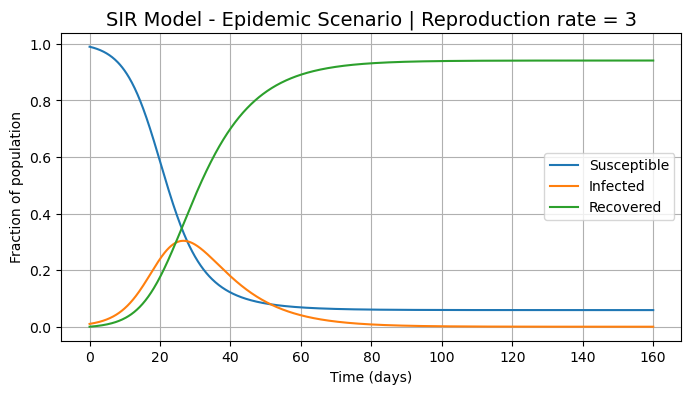

In [5]:
plt.figure(figsize=(8, 4))

plt.plot(t, S_epidemic, label="Susceptible")
plt.plot(t, I_epidemic, label="Infected")
plt.plot(t, R_epidemic, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Fraction of population")
plt.title("SIR Model - Epidemic Scenario | Reproduction rate = 3", fontsize=14)
plt.legend()
plt.grid()

plt.show()

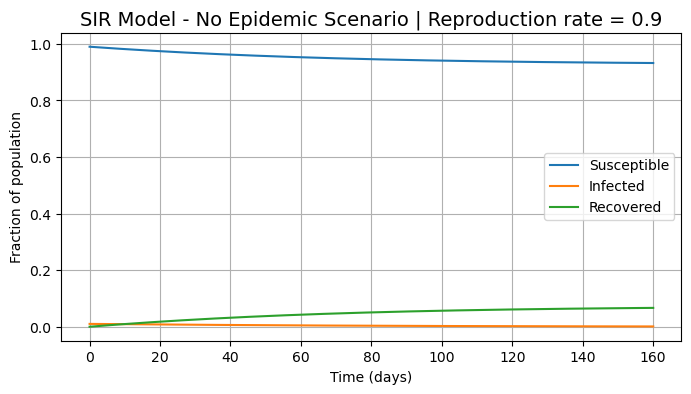

In [6]:
plt.figure(figsize=(8, 4))

plt.plot(t, S_no_epidemic, label="Susceptible")
plt.plot(t, I_no_epidemic, label="Infected")
plt.plot(t, R_no_epidemic, label="Recovered")

plt.xlabel("Time (days)")
plt.ylabel("Fraction of population")
plt.title("SIR Model - No Epidemic Scenario | Reproduction rate = 0.9", fontsize=14)
plt.legend()
plt.grid()

plt.show()

Now we can look at the phase plots of these two scenarios. The phase plot show how the how the system evolves and where it ends from different initial conditions. The initial conditions either lay on a gional line where S0 + I0 = 1, or they lay on the x-axis where a certain fration of the populaiton is already recovered (from vaccines or something else). Every condition must satisfy S0 + I0 + R0 = 1.

In [7]:
initial_conditions = [
    # On diagonal: S0 + I0 = 1
    [0.1, 0.9, 0.0],
    [0.2, 0.8, 0.0],
    [0.3, 0.7, 0.0],
    [0.4, 0.6, 0.0],
    [0.5, 0.5, 0.0],
    [0.6, 0.4, 0.0],
    [0.7, 0.3, 0.0],
    [0.8, 0.2, 0.0],
    [0.9, 0.1, 0.0],
    [0.99, 0.01, 0.0],

    # On S-axis: I0 = 0
    [0.1, 0.01, 0.89],
    [0.2, 0.01, 0.79],
    [0.3, 0.01, 0.69],
    [0.4, 0.01, 0.59],
    [0.5, 0.01, 0.49],
    [0.6, 0.01, 0.39],
    [0.7, 0.01, 0.29],
    [0.8, 0.01, 0.19],
    [0.9, 0.01, 0.09],
    [0.99, 0.01, 0.0]
]

In [8]:
solutions = []

for y0 in initial_conditions:
    solution = odeint(
        sir_model,
        y0,
        t,
        args=(beta_epidemic, gamma)
    )
    solutions.append(solution)

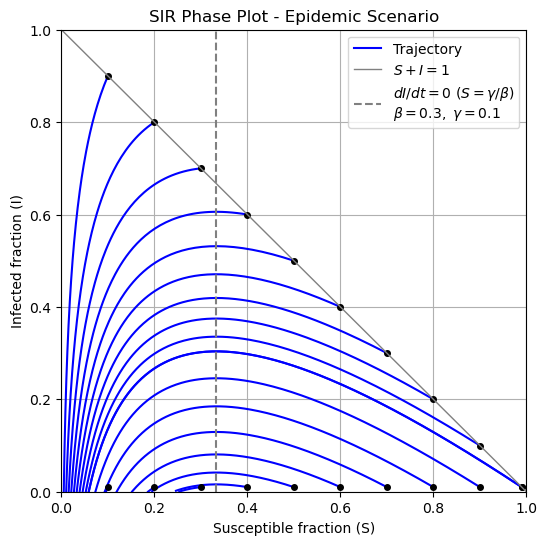

In [ ]:
plt.figure(figsize=(6, 6))

# Plot trajectories
for i, solution in enumerate(solutions):
    S = solution[:, 0]
    I = solution[:, 1]

    #only add label once
    if i == 0:
        plt.plot(S, I, color="blue", label="Trajectory")
    else:
        plt.plot(S, I, color="blue")

#plot initial conditions
for S0, I0, R0 in initial_conditions:
    plt.plot(S0, I0, "ko", markersize=4)

#plot diagonal line S + I = 1
S_line = np.linspace(0, 1, 100)

plt.plot(
    S_line,
    1 - S_line,
    color="gray",
    linewidth=1,
    label=r"$S + I = 1$"
)

# dI/dt = 0 threshold
S_threshold = gamma / beta_epidemic

plt.axvline(
    S_threshold,
    color="gray",
    linestyle="--",
    label=rf"$dI/dt = 0$ ($S = \gamma/\beta$)" + "\n" +
          rf"$\beta = {beta_epidemic},\ \gamma = {gamma}$"
)

plt.xlabel("Susceptible fraction (S)")
plt.ylabel("Infected fraction (I)")
plt.title("SIR Phase Plot - Epidemic Scenario")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid()

plt.show()

In [10]:
solutions_2 = []

for y0 in initial_conditions:
    solution = odeint(
        sir_model,
        y0,
        t,
        args=(beta_no_epidemic, gamma)
    )
    solutions_2.append(solution)

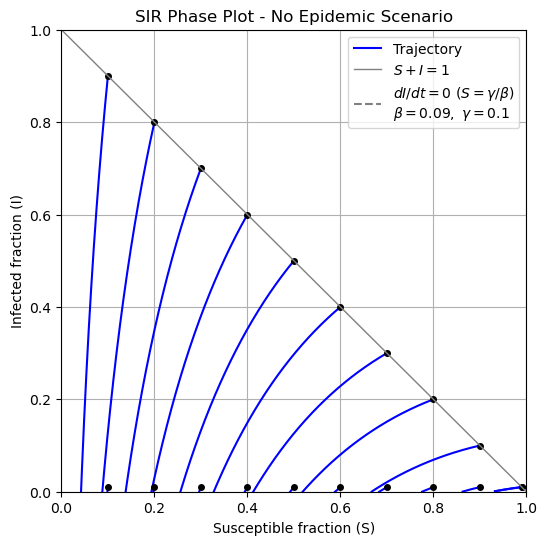

In [11]:
plt.figure(figsize=(6, 6))

# Plot trajectories
for i, solution in enumerate(solutions_2):
    S = solution[:, 0]
    I = solution[:, 1]

    #only add label once
    if i == 0:
        plt.plot(S, I, color="blue", label="Trajectory")
    else:
        plt.plot(S, I, color="blue")

# Plot initial conditions
for S0, I0, R0 in initial_conditions:
    plt.plot(S0, I0, "ko", markersize=4)

#plot diagonal line S + I = 1
S_line = np.linspace(0, 1, 100)

plt.plot(
    S_line,
    1 - S_line,
    color="gray",
    linewidth=1,
    label=r"$S + I = 1$"
)

#plot dI/dt = 0 threshold
S_threshold = gamma / beta_no_epidemic

plt.axvline(
    S_threshold,
    color="gray",
    linestyle="--",
    label=rf"$dI/dt = 0$ ($S = \gamma/\beta$)" + "\n" +
          rf"$\beta = {beta_no_epidemic},\ \gamma = {gamma}$"
)

plt.xlabel("Susceptible fraction (S)")
plt.ylabel("Infected fraction (I)")
plt.title("SIR Phase Plot - No Epidemic Scenario")

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid()

plt.show()

Problem 1.2 - Analyzing a real scenario

In [12]:
#setting up the data
N = 763
days = np.arange(0, 15)

infected_data = np.array([
    1, 3, 8, 28, 75,
    221, 291, 255, 235, 190,
    125, 70, 28, 12, 5
])

infected_fraction_data = infected_data / N

#initial conditions for fitting
I0 = 1/N
S0 = 1 - I0
R0 = 0.0

y0 = [S0, I0, R0]

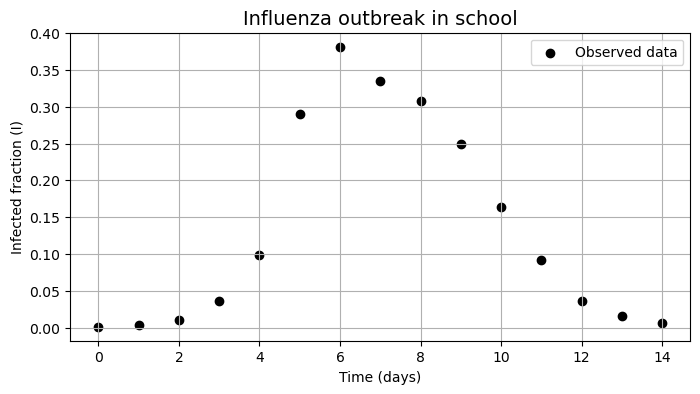

In [13]:
#plot observed data
plt.figure(figsize=(8, 4))

plt.scatter(
    days,
    infected_fraction_data,
    color="black",
    label="Observed data"
)

plt.xlabel("Time (days)")
plt.ylabel("Infected fraction (I)")
plt.title("Influenza outbreak in school",fontsize=14)
plt.legend()
plt.grid()

plt.show()

In [14]:
#simulate different values of beta and gamma to find best fit
def simulate_sir(params):
    beta, gamma = params

    solution = odeint(
        sir_model,
        y0,
        days,
        args=(beta, gamma)
    )

    I_simulated = solution[:, 1]
    #print (f"Simulated infected fraction: {I_simulated}")

    return I_simulated

We need to evaluate how well a particular beta and gamma pair fits the observations. The sum of squared errors will be used for this task. 
$$
\text{SSE} = \sum_{t=0}^{14} \left(I_{\text{simulated}}(t) - I_{\text{observed}}(t)\right)^2
$$


In [15]:
def error(params):
    I_simulated = simulate_sir(params)

    return np.sum((I_simulated - infected_fraction_data) ** 2)

In [16]:
from scipy.optimize import minimize
initial_guess = [1.0, 0.5]

result = minimize(
    error,
    initial_guess,
    bounds=[(0, None), (0, None)]
)

beta_fitted, gamma_fitted = result.x
R_nought_fitted = beta_fitted / gamma_fitted

print("Fitted beta:", beta_fitted)
print("Fitted gamma:", gamma_fitted)
print("R_nought:", R_nought_fitted)

Fitted beta: 1.6651166610316903
Fitted gamma: 0.4476108349788452
R_nought: 3.7200097292336243


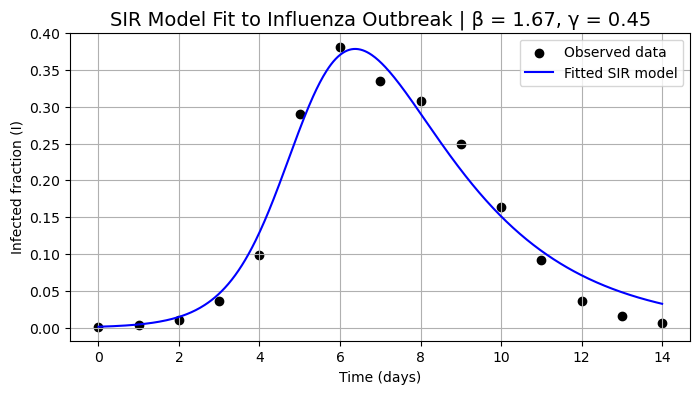

In [17]:
t = np.linspace(0, 14, 500)

solution = odeint(
    sir_model,
    y0,
    t,
    args=(beta_fitted, gamma_fitted)
)

I_data = solution[:, 1]

plt.figure(figsize=(8, 4))

#observed data
plt.scatter(
    days,
    infected_fraction_data,
    color="black",
    label="Observed data"
)

#smooth fitted SIR curve
plt.plot(
    t,
    I_data,
    color="blue",
    label="Fitted SIR model"
)

plt.xlabel("Time (days)")
plt.ylabel("Infected fraction (I)")
plt.title(f"SIR Model Fit to Influenza Outbreak | β = {beta_fitted:.2f}, γ = {gamma_fitted:.2f}", fontsize=14)
plt.legend()
plt.grid()

plt.show()

1.3 Vacination Strategies:
Students who get vacinated immediatly move from S (susceptible) class to the R (recovered) class.
We estimated the beta and gamma for this scenario, which means we can vaccinate enough people at t=0 until the effective reproduction number is equal to 1, so the virus does not spread. S = 1/R0, 1 - v = 1/R0, v = 1 - 1/R0. 
(v = vaccinated fraction, R0 = R_nought)

The second strategy is to vaccinate 10 students everyday until the end of the epidemic.

### Hypothesis

Vaccinating the critical fraction of susceptible students before the outbreak
will prevent the infection from initially growing, since the effective
reproduction number is reduced to 1.

Vaccinating 10 susceptible students per day after the outbreak begins is
expected to reduce the size of the outbreak, but may be less effective because
the disease can continue spreading while the susceptible population is
gradually being vaccinated.

In [18]:
#find how many students to vacinate to prevent an epidemic
critical_vaccination_fraction = 1 - (1 / R_nought_fitted)

print("Critical vaccination fraction:", critical_vaccination_fraction)
print("Percentage vaccinated:", critical_vaccination_fraction * 100)

students_to_vaccinate = np.ceil(
    critical_vaccination_fraction * (N - 1)
)

print("Students to vaccinate:", students_to_vaccinate)

Critical vaccination fraction: 0.7311834987576727
Percentage vaccinated: 73.11834987576728
Students to vaccinate: 558.0


In [19]:
#initial conditions
I0 = 1 / N
R0 = students_to_vaccinate / N
S0 = (N - 1 - students_to_vaccinate) / N

vaccination_rate = 10 / N

y0_critical = [S0, I0, R0]

In [20]:
t_vaccination = np.linspace(0, 60, 1000)

#simulate the SIR model with vaccination for 60 days
solution_critical = odeint(
    sir_model,
    y0_critical,
    t_vaccination,
    args=(beta_fitted, gamma_fitted)
)

S_critical = solution_critical[:, 0]
I_critical = solution_critical[:, 1]
R_critical = solution_critical[:, 2]

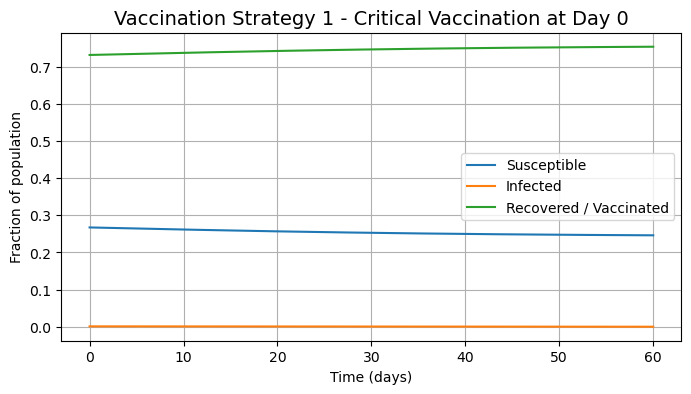

In [21]:
plt.figure(figsize=(8, 4))

plt.plot(t_vaccination, S_critical, label="Susceptible")
plt.plot(t_vaccination, I_critical, label="Infected")
plt.plot(t_vaccination, R_critical, label="Recovered / Vaccinated")

plt.xlabel("Time (days)")
plt.ylabel("Fraction of population")
plt.title("Vaccination Strategy 1 - Critical Vaccination at Day 0", fontsize=14)

plt.legend()
plt.grid()
plt.show()

In [22]:
def sir_vaccination_model(y, t, beta, gamma, vaccination_rate):
    S, I, R = y

    if S > 0:
        vaccination = min(vaccination_rate, S)
    else:
        vaccination = 0

    dSdt = -beta * S * I - vaccination
    dIdt = beta * S * I - gamma * I
    dRdt = gamma * I + vaccination

    return [dSdt, dIdt, dRdt]

In [23]:
S0 = (N - 1) / N
I0 = 1 / N
R0 = 0

y0_daily = [S0, I0, R0]

solution_daily = odeint(
    sir_vaccination_model,
    y0_daily,
    t_vaccination,
    args=(beta_fitted, gamma_fitted, vaccination_rate)
)

S_daily = solution_daily[:, 0]
I_daily = solution_daily[:, 1]
R_daily = solution_daily[:, 2]

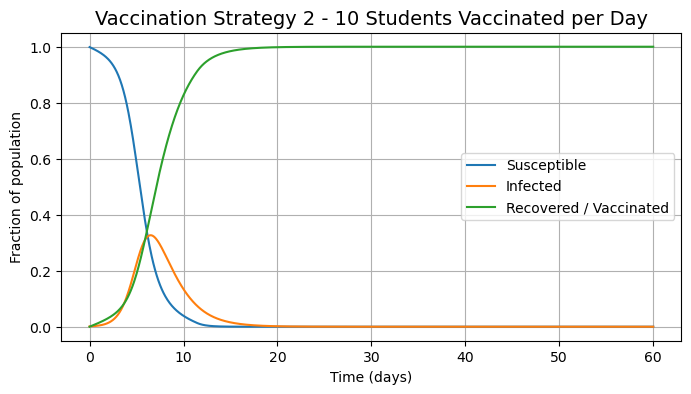

In [24]:
plt.figure(figsize=(8, 4))

plt.plot(t_vaccination, S_daily, label="Susceptible")
plt.plot(t_vaccination, I_daily, label="Infected")
plt.plot(t_vaccination, R_daily, label="Recovered / Vaccinated")

plt.xlabel("Time (days)")
plt.ylabel("Fraction of population")
plt.title("Vaccination Strategy 2 - 10 Students Vaccinated per Day", fontsize=14)

plt.legend()
plt.grid()
plt.show()

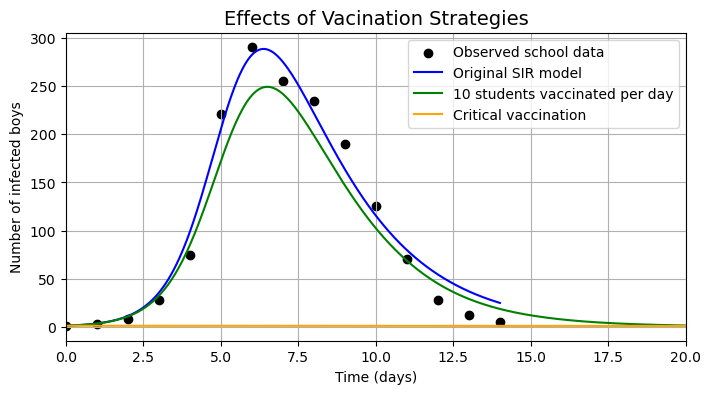

In [25]:
plt.figure(figsize=(8, 4))

#actual school data
plt.scatter(
    days,
    infected_data,
    color="black",
    label="Observed school data"
)

#original fitted SIR model
plt.plot(
    t,
    I_data * N,
    color="blue",
    label="Original SIR model"
)

plt.plot(
    t_vaccination,
    I_daily * N,
    color="green",
    label="10 students vaccinated per day"
)

#critical vaccination strategy
plt.plot(
    t_vaccination,
    I_critical * N,
    color="orange",
    label="Critical vaccination"
)

plt.xlabel("Time (days)")
plt.ylabel("Number of infected boys")
plt.title("Effects of Vacination Strategies", fontsize=14)

plt.xlim(0, 20)
plt.legend()
plt.grid()

plt.show()

Problem 2: Demography
2.1: To add birth and death rates, we will introduce a new variable "mu". People are born into the susceptible group at rate mu and die at rates mu*S,mu*I, and mu*R.
     This means that the overall population remains constant.

In [26]:
#model with demography (births and deaths)
def sir_demography_model(y, t, beta, gamma, mu):
    S, I, R = y

    dSdt = mu - beta * S * I - mu * S
    dIdt = beta * S * I - gamma * I - mu * I
    dRdt = gamma * I - mu * R

    return [dSdt, dIdt, dRdt]

In [27]:
#initial conditions
beta = 0.3
gamma = 0.1
mu = 0.01

S0 = 0.99
I0 = 0.01
R0 = 0

y0 = [S0, I0, R0]

t_demography = np.linspace(0, 500, 2500)

In [28]:
solution_demography = odeint(
    sir_demography_model,
    y0,
    t_demography,
    args=(beta, gamma, mu)
)

S_demography = solution_demography[:, 0]
I_demography = solution_demography[:, 1]
R_demography = solution_demography[:, 2]

Equilibrium:

In [29]:
S_endemic = (gamma + mu) / beta

I_endemic = (
    mu * (1 - S_endemic) / (gamma + mu)
)

R_endemic = 1 - S_endemic - I_endemic

print("Endemic S:", S_endemic)
print("Endemic I:", I_endemic)
print("Endemic R:", R_endemic)

Endemic S: 0.3666666666666667
Endemic I: 0.05757575757575757
Endemic R: 0.5757575757575757


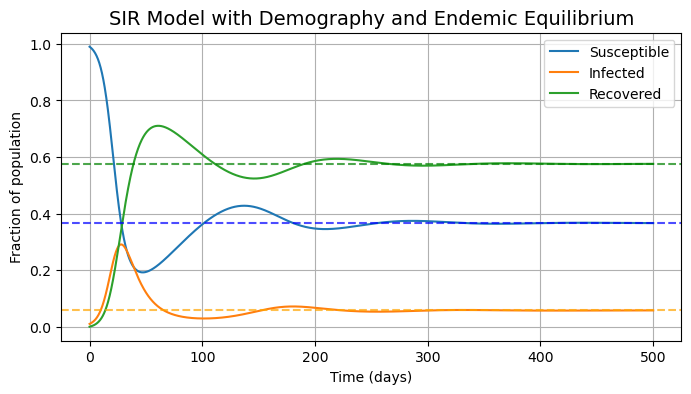

In [30]:
plt.figure(figsize=(8, 4))

plt.plot(t_demography, S_demography, label="Susceptible")
plt.plot(t_demography, I_demography, label="Infected")
plt.plot(t_demography, R_demography, label="Recovered")

plt.axhline(S_endemic, linestyle="--", color="blue", alpha=0.7)
plt.axhline(I_endemic, linestyle="--", color="orange", alpha=0.7)
plt.axhline(R_endemic, linestyle="--", color="green", alpha=0.7)

plt.xlabel("Time (days)")
plt.ylabel("Fraction of population")
plt.title("SIR Model with Demography and Endemic Equilibrium", fontsize=14)

plt.legend()
plt.grid()
plt.show()

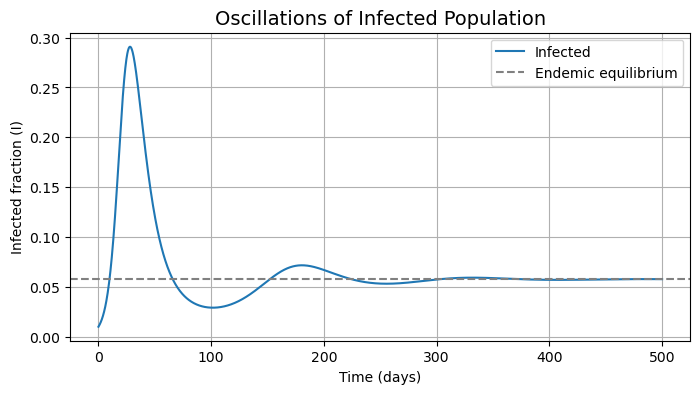

In [31]:
plt.figure(figsize=(8, 4))

plt.plot(
    t_demography,
    I_demography,
    label="Infected"
)

plt.axhline(
    I_endemic,
    color="gray",
    linestyle="--",
    label="Endemic equilibrium"
)

plt.xlabel("Time (days)")
plt.ylabel("Infected fraction (I)")
plt.title("Oscillations of Infected Population", fontsize=14)

plt.legend()
plt.grid()
plt.show()

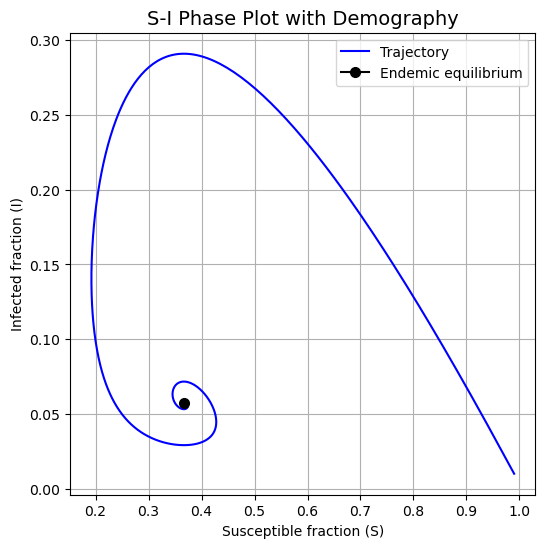

In [32]:
plt.figure(figsize=(6, 6))

plt.plot(
    S_demography,
    I_demography,
    color="blue",
    label="Trajectory"
)

plt.plot(
    S_endemic,
    I_endemic,
    color="black",
    marker="o",
    markersize=7,
    label="Endemic equilibrium"
)

plt.xlabel("Susceptible fraction (S)")
plt.ylabel("Infected fraction (I)")
plt.title("S-I Phase Plot with Demography", fontsize=14)

plt.legend()
plt.grid()
plt.show()

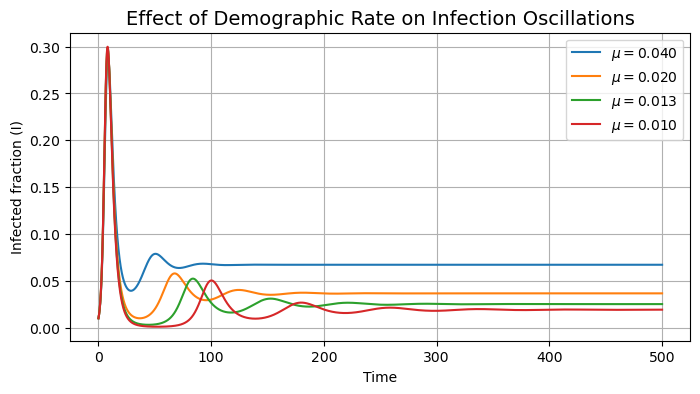

In [33]:
beta = 1
gamma = 1 / 3

mu_values = [
    1 / 25,
    1 / 50,
    1 / 75,
    1 / 100
]

t_demography = np.linspace(0, 500, 5000)

S0 = 0.99
I0 = 0.01
R0 = 0
y0 = [S0, I0, R0]

plt.figure(figsize=(8, 4))

for mu_value in mu_values:
    solution = odeint(
        sir_demography_model,
        y0,
        t_demography,
        args=(beta, gamma, mu_value)
    )

    I = solution[:, 1]

    plt.plot(
        t_demography,
        I,
        label=rf"$\mu = {mu_value:.3f}$"
    )

plt.xlabel("Time")
plt.ylabel("Infected fraction (I)")
plt.title("Effect of Demographic Rate on Infection Oscillations", fontsize=14)

plt.legend()
plt.grid()
plt.show()

In [34]:
initial_conditions_demography = [
    [0.1, 0.9, 0.0],
    [0.2, 0.8, 0.0],
    [0.3, 0.7, 0.0],
    [0.4, 0.6, 0.0],
    [0.5, 0.5, 0.0],
    [0.6, 0.4, 0.0],
    [0.7, 0.3, 0.0],
    [0.8, 0.2, 0.0],
    [0.9, 0.1, 0.0],
    [0.99, 0.01, 0.0]
]

beta = 1
gamma = 1 / 3
mu = 1 / 60

S_endemic = (gamma + mu) / beta

I_endemic = (
    mu * (1 - S_endemic) / (gamma + mu)
)

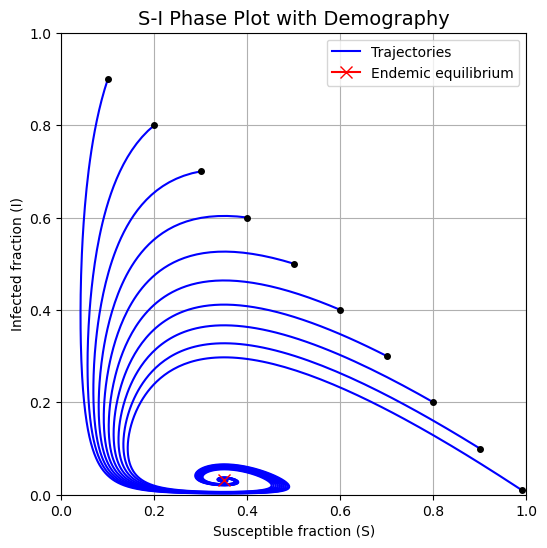

In [35]:
plt.figure(figsize=(6, 6))

for i, y0_phase in enumerate(initial_conditions_demography):
    solution = odeint(
        sir_demography_model,
        y0_phase,
        t_demography,
        args=(beta, gamma, mu)
    )

    S = solution[:, 0]
    I = solution[:, 1]

    if i == 0:
        plt.plot(S, I, color="blue", label="Trajectories")
    else:
        plt.plot(S, I, color="blue")

    plt.plot(
        y0_phase[0],
        y0_phase[1],
        color="black",
        marker="o",
        markersize=4
    )

plt.plot(
    S_endemic,
    I_endemic,
    color="red",
    marker="x",
    markersize=8,
    label="Endemic equilibrium"
)

plt.xlabel("Susceptible fraction (S)")
plt.ylabel("Infected fraction (I)")
plt.title("S-I Phase Plot with Demography", fontsize=14)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid()
plt.show()

Fourier Analysis:

In [36]:
N = len(I_demography)

dt = t_demography[1] - t_demography[0]
fs = 1 / dt

print("Number of samples:", N)
print("Sampling interval:", dt)
print("Sampling frequency:", fs)

I_centered = I_demography - np.mean(I_demography)

#apply Hann window
window = np.hanning(N)
I_windowed = I_centered * window

I_fft = np.fft.rfft(I_windowed)

#compute frequencies corresponding to FFT output
frequencies = np.fft.rfftfreq(
    N,
    d=dt
)
#compute amplitude spectrum
amplitude = np.abs(I_fft) / (N * np.mean(window))
amplitude[1:-1] *= 2

Number of samples: 2500
Sampling interval: 0.10002000400080016
Sampling frequency: 9.998


Dominant frequency: 0.0119976
Dominant period: 83.35000333400014
Dominant amplitude: 0.010339330759941683


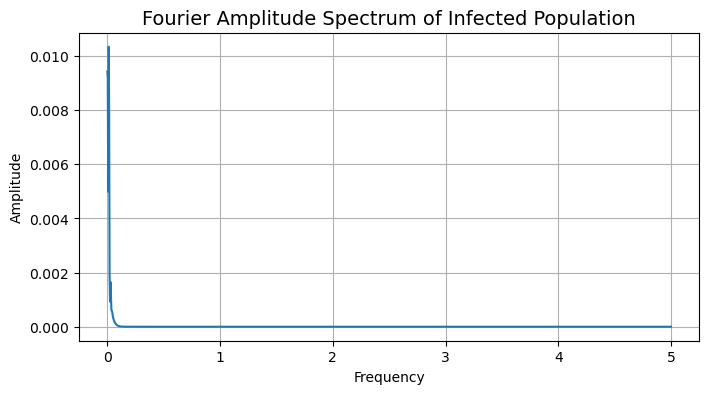

In [37]:
#find dominant frequency, ignoring DC
peak_index = np.argmax(amplitude[1:]) + 1
dominant_frequency = frequencies[peak_index]
dominant_period = 1 / dominant_frequency
dominant_amplitude = amplitude[peak_index]

print("Dominant frequency:", dominant_frequency)
print("Dominant period:", dominant_period)
print("Dominant amplitude:", dominant_amplitude)


plt.figure(figsize=(8, 4))

plt.plot(frequencies, amplitude)

plt.xlabel("Frequency")
plt.ylabel("Amplitude")
plt.title("Fourier Amplitude Spectrum of Infected Population", fontsize=14)

plt.grid()
plt.show()

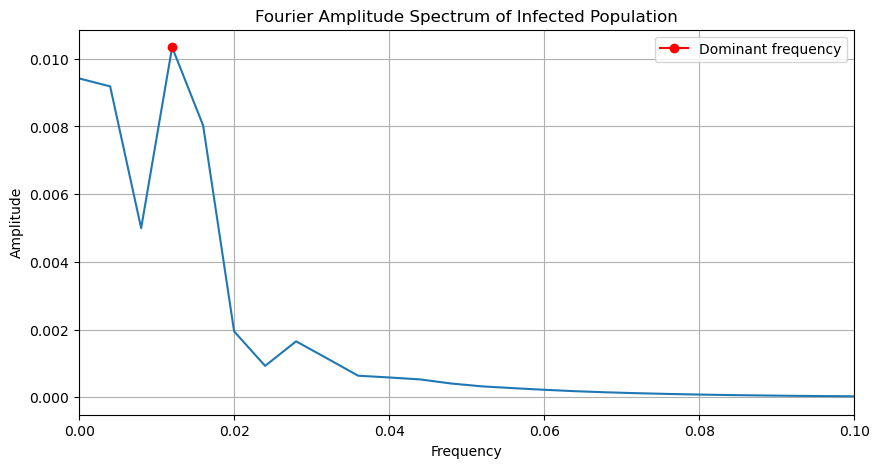

In [38]:
plt.figure(figsize=(10, 5))

plt.plot(frequencies, amplitude)

plt.plot(
    dominant_frequency,
    dominant_amplitude,
    color="red",
    marker="o",
    label="Dominant frequency"
)

plt.xlabel("Frequency")
plt.ylabel("Amplitude")
plt.title("Fourier Amplitude Spectrum of Infected Population")

plt.xlim(0, 0.1)
plt.legend()
plt.grid()
plt.show()

2.2: Mortality

In [39]:
def sir_mortality_model(y, t, beta, gamma, mu, alpha):
    S, I, R = y

    N = S + I + R

    infection = beta * S * I / N

    dSdt = mu * N - infection - mu * S
    dIdt = infection - gamma * I - mu * I - alpha * I
    dRdt = gamma * I - mu * R

    return [dSdt, dIdt, dRdt]

In [40]:
#conditions
alpha_values = [0, 0.25, 0.5, 0.6, 0.8]

beta = 1
gamma = 1 / 3
mu = 1 / 60

N0 = 1000

S0 = 999
I0 = 1
R0 = 0

y0_mortality = [S0, I0, R0]

t_mortality = np.linspace(0, 500, 5000)

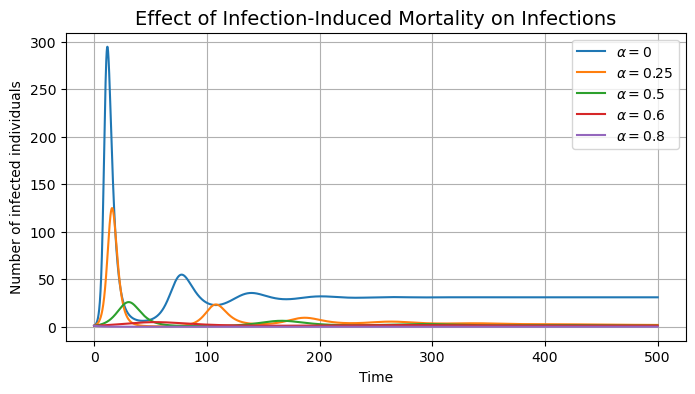

In [41]:
plt.figure(figsize=(8, 4))

for alpha in alpha_values:
    solution = odeint(
        sir_mortality_model,
        y0_mortality,
        t_mortality,
        args=(beta, gamma, mu, alpha)
    )

    I = solution[:, 1]

    plt.plot(
        t_mortality,
        I,
        label=rf"$\alpha = {alpha}$"
    )

plt.xlabel("Time")
plt.ylabel("Number of infected individuals")
plt.title("Effect of Infection-Induced Mortality on Infections", fontsize=14)

plt.legend()
plt.grid()
plt.show()

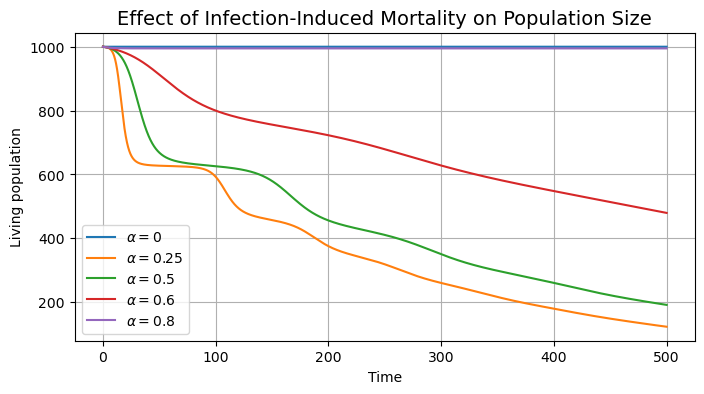

In [42]:
plt.figure(figsize=(8, 4))

for alpha in alpha_values:
    solution = odeint(
        sir_mortality_model,
        y0_mortality,
        t_mortality,
        args=(beta, gamma, mu, alpha)
    )

    S = solution[:, 0]
    I = solution[:, 1]
    R = solution[:, 2]

    N = S + I + R

    plt.plot(
        t_mortality,
        N,
        label=rf"$\alpha = {alpha}$"
    )

plt.xlabel("Time")
plt.ylabel("Living population")
plt.title("Effect of Infection-Induced Mortality on Population Size", fontsize=14)

plt.legend()
plt.grid()
plt.show()

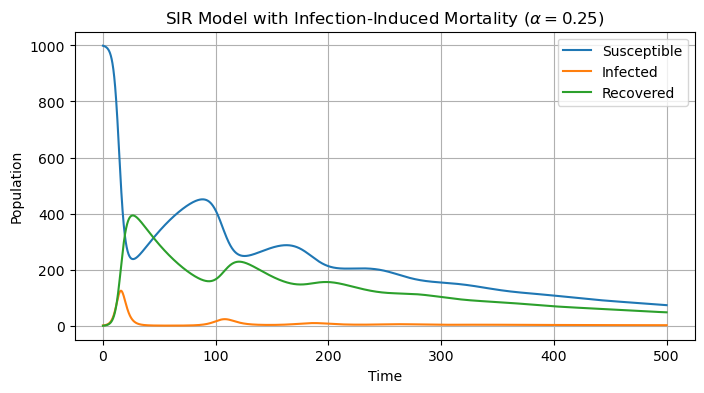

In [43]:
alpha = 0.25

solution_high_mortality = odeint(
    sir_mortality_model,
    y0_mortality,
    t_mortality,
    args=(beta, gamma, mu, alpha)
)

S_high = solution_high_mortality[:, 0]
I_high = solution_high_mortality[:, 1]
R_high = solution_high_mortality[:, 2]

plt.figure(figsize=(8, 4))

plt.plot(t_mortality, S_high, label="Susceptible")
plt.plot(t_mortality, I_high, label="Infected")
plt.plot(t_mortality, R_high, label="Recovered")

plt.xlabel("Time")
plt.ylabel("Population")
plt.title(r"SIR Model with Infection-Induced Mortality ($\alpha = 0.25$)")

plt.legend()
plt.grid()
plt.show()

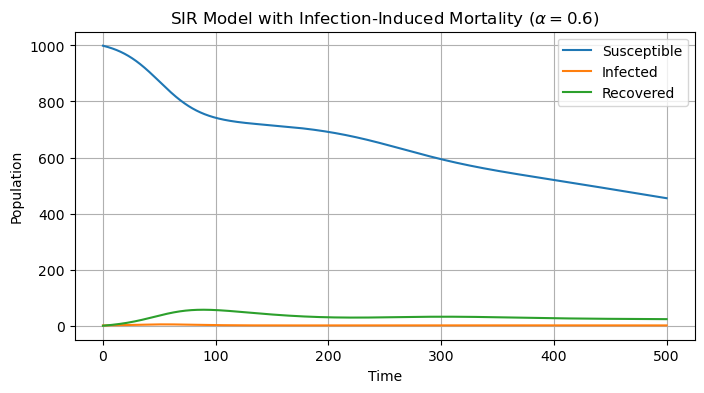

In [44]:
alpha = 0.6

solution_high_mortality = odeint(
    sir_mortality_model,
    y0_mortality,
    t_mortality,
    args=(beta, gamma, mu, alpha)
)

S_high = solution_high_mortality[:, 0]
I_high = solution_high_mortality[:, 1]
R_high = solution_high_mortality[:, 2]

plt.figure(figsize=(8, 4))

plt.plot(t_mortality, S_high, label="Susceptible")
plt.plot(t_mortality, I_high, label="Infected")
plt.plot(t_mortality, R_high, label="Recovered")

plt.xlabel("Time")
plt.ylabel("Population")
plt.title(r"SIR Model with Infection-Induced Mortality ($\alpha = 0.6$)")

plt.legend()
plt.grid()
plt.show()

Problem 3: SIR model variant
I have decided to test adn analyze the SEIR model with demography.

S + E + I + R = 1

\[
\frac{1}{\sigma}=\text{average time in the exposed compartment}.
\]

In [45]:
def seir_model(y, t, beta, gamma, sigma, mu):
    S, E, I, R = y

    dSdt = mu - beta * S * I - mu * S
    dEdt = beta * S * I - sigma * E - mu * E
    dIdt = sigma * E - gamma * I - mu * I
    dRdt = gamma * I - mu * R

    return [dSdt, dEdt, dIdt, dRdt]

In [46]:
beta = 1
gamma = 1 / 3
mu = 1 / 60
sigma = 1 / 5

S0 = 0.99
E0 = 0.0
I0 = 0.01
R0 = 0.0

y0_seir = [S0, E0, I0, R0]

t_seir = np.linspace(0, 500, 5000)

In [47]:
solution_seir = odeint(
    seir_model,
    y0_seir,
    t_seir,
    args=(beta, gamma, sigma, mu)
)

S_seir = solution_seir[:, 0]
E_seir = solution_seir[:, 1]
I_seir = solution_seir[:, 2]
R_seir = solution_seir[:, 3]

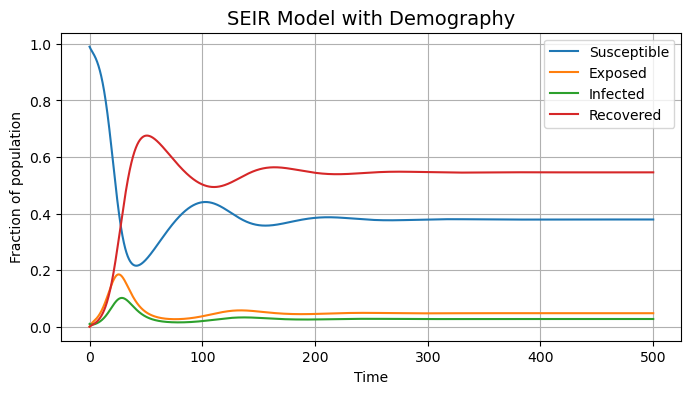

In [48]:
plt.figure(figsize=(8, 4))

plt.plot(t_seir, S_seir, label="Susceptible")
plt.plot(t_seir, E_seir, label="Exposed")
plt.plot(t_seir, I_seir, label="Infected")
plt.plot(t_seir, R_seir, label="Recovered")

plt.xlabel("Time")
plt.ylabel("Fraction of population")
plt.title("SEIR Model with Demography", fontsize=14)

plt.legend()
plt.grid()
plt.show()

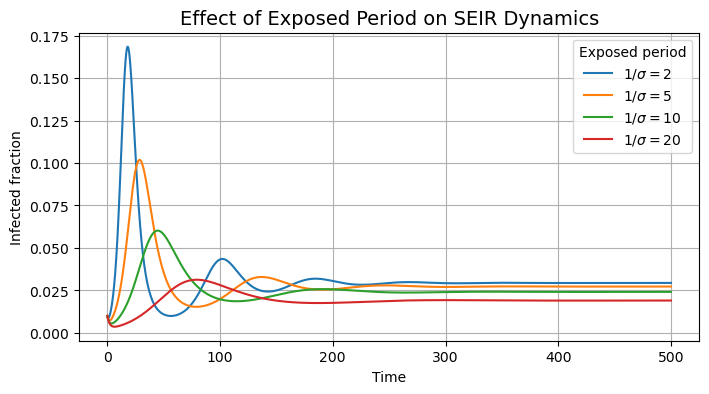

In [49]:
#all parameters are constant 
sigma_values = [
    1 / 2,
    1 / 5,
    1 / 10,
    1 / 20
]

plt.figure(figsize=(8, 4))

for sigma_value in sigma_values:
    solution = odeint(
        seir_model,
        y0_seir,
        t_seir,
        args=(beta, gamma, sigma_value, mu)
    )

    I = solution[:, 2]

    plt.plot(
        t_seir,
        I,
        label=rf"$1/\sigma = {1/sigma_value:.0f}$"
    )

plt.xlabel("Time")
plt.ylabel("Infected fraction")
plt.title("Effect of Exposed Period on SEIR Dynamics", fontsize=14)

plt.legend(title="Exposed period")
plt.grid()
plt.show()

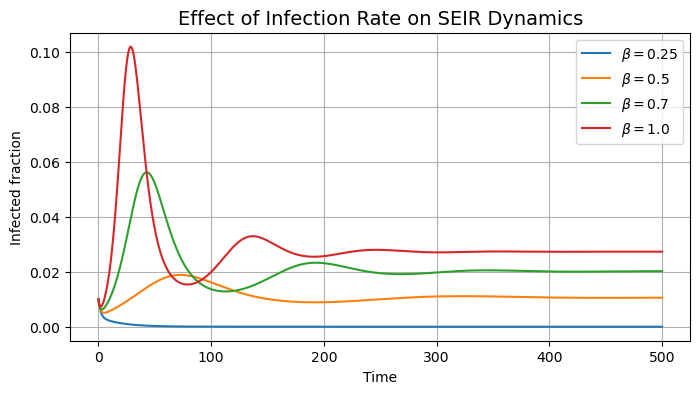

In [50]:
beta_values = [0.25, 0.5, 0.7, 1.0]

gamma = 1 / 3
mu = 1 / 60
sigma = 1 / 5

plt.figure(figsize=(8, 4))

for beta_value in beta_values:
    solution = odeint(
        seir_model,
        y0_seir,
        t_seir,
        args=(beta_value, gamma, sigma, mu)
    )

    I = solution[:, 2]

    plt.plot(
        t_seir,
        I,
        label=rf"$\beta = {beta_value}$"
    )

plt.xlabel("Time")
plt.ylabel("Infected fraction")
plt.title("Effect of Infection Rate on SEIR Dynamics", fontsize=14)

plt.legend()
plt.grid()
plt.show()

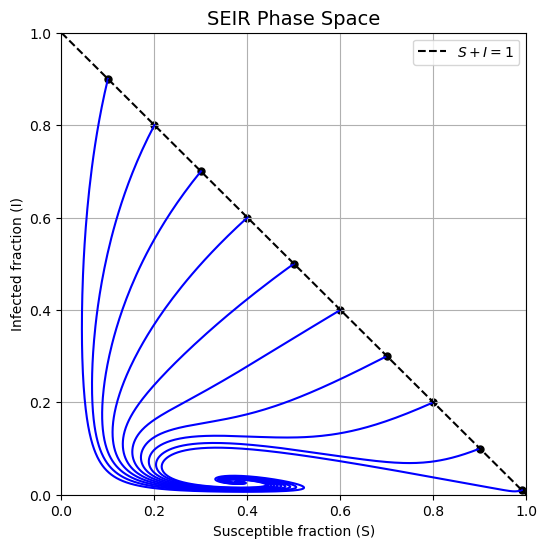

In [51]:
beta = 1
gamma = 1 / 3
sigma = 1 / 5
mu = 1 / 60

initial_conditions_seir = [
    [0.1, 0.0, 0.9, 0.0],
    [0.2, 0.0, 0.8, 0.0],
    [0.3, 0.0, 0.7, 0.0],
    [0.4, 0.0, 0.6, 0.0],
    [0.5, 0.0, 0.5, 0.0],
    [0.6, 0.0, 0.4, 0.0],
    [0.7, 0.0, 0.3, 0.0],
    [0.8, 0.0, 0.2, 0.0],
    [0.9, 0.0, 0.1, 0.0],
    [0.99, 0.0, 0.01, 0.0]
]

plt.figure(figsize=(6, 6))

for y0 in initial_conditions_seir:

    solution = odeint(
        seir_model,
        y0,
        t_seir,
        args=(beta, gamma, sigma, mu)
    )

    S = solution[:, 0]
    I = solution[:, 2]

    #phase-space trajectory
    plt.plot(S, I, color="blue")

    #initial position
    plt.scatter(S[0], I[0], color="black", s=25)

#diagonal containing the initial conditions: S + I = 1
S_line = np.linspace(0, 1, 100)
plt.plot(
    S_line,
    1 - S_line,
    color="black",
    linestyle="--",
    label=r"$S + I = 1$"
)

plt.xlabel("Susceptible fraction (S)")
plt.ylabel("Infected fraction (I)")
plt.title("SEIR Phase Space", fontsize=14)

plt.xlim(0, 1)
plt.ylim(0, 1)

plt.legend()
plt.grid()
plt.show()

In [52]:
def seir_seasonal_model(y, t, beta0, beta1, gamma, sigma, mu):
    S, E, I, R = y

    beta_t = beta0 * (1 + beta1 * np.cos(2 * np.pi * t))

    dSdt = mu - beta_t * S * I - mu * S
    dEdt = beta_t * S * I - sigma * E - mu * E
    dIdt = sigma * E - gamma * I - mu * I
    dRdt = gamma * I - mu * R

    return [dSdt, dEdt, dIdt, dRdt]

In [53]:
mu = 0.02
beta0 = 1250

sigma = 365 / 8
gamma = 365 / 5

S0 = 6e-2
E0 = 1e-3
I0 = 1e-3
R0 = 1 - S0 - E0 - I0

y0_seasonal = [S0, E0, I0, R0]

t_seasonal = np.linspace(0, 50, 10000)

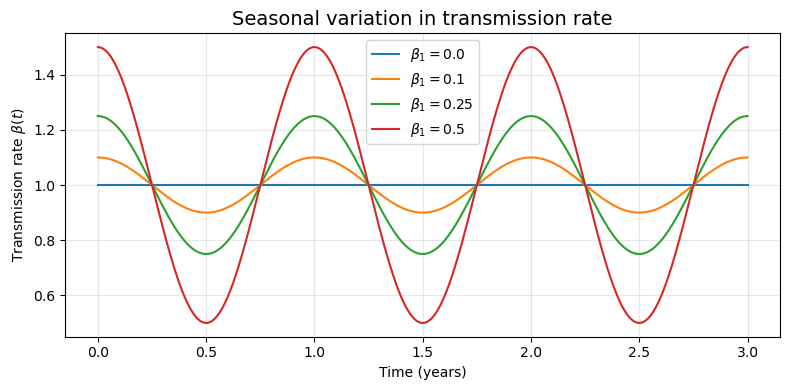

In [54]:
beta0 = 1.0
beta1_values = [0.0, 0.1, 0.25, 0.5]

t_beta = np.linspace(0, 3, 1000)

plt.figure(figsize=(8, 4))

for beta1 in beta1_values:
    beta_t = beta0 * (1 + beta1 * np.cos(2 * np.pi * t_beta))

    plt.plot(
        t_beta,
        beta_t,
        label=rf"$\beta_1={beta1}$"
    )

plt.xlabel("Time (years)")
plt.ylabel(r"Transmission rate $\beta(t)$")
plt.title("Seasonal variation in transmission rate", fontsize=14)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
def seir_seasonal(y, t, beta0, beta1, gamma, sigma, mu, T):
    S, E, I, R = y

    beta_t = beta0 * (
        1 + beta1 * np.cos(2 * np.pi * t / T)
    )

    dSdt = mu - beta_t * S * I - mu * S
    dEdt = beta_t * S * I - sigma * E - mu * E
    dIdt = sigma * E - gamma * I - mu * I
    dRdt = gamma * I - mu * R

    return [dSdt, dEdt, dIdt, dRdt]

In [56]:
beta0 = 1.5
gamma = 0.5
sigma = 0.5
mu = 0.1

T = 20

S0 = 0.85
E0 = 0.05
I0 = 0.05
R0 = 0.05

y0_seasonal = [S0, E0, I0, R0]

t_seasonal = np.linspace(0, 200, 5000)

beta1_values = [0.0, 0.2, 0.5, 0.8]

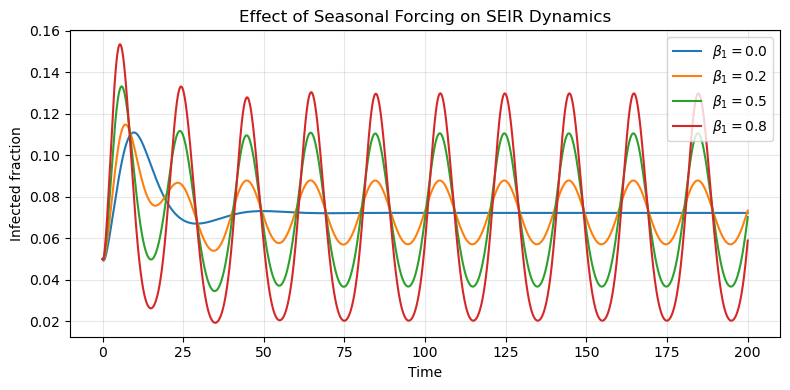

In [57]:
plt.figure(figsize=(8, 4))

for beta1 in beta1_values:

    solution = odeint(
        seir_seasonal,
        y0_seasonal,
        t_seasonal,
        args=(beta0, beta1, gamma, sigma, mu, T)
    )

    I = solution[:, 2]

    plt.plot(
        t_seasonal,
        I,
        label=rf"$\beta_1={beta1}$"
    )

plt.xlabel("Time")
plt.ylabel("Infected fraction")
plt.title("Effect of Seasonal Forcing on SEIR Dynamics")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [58]:
# Keep all parameters fixed
beta0 = 1.5
beta1 = 0.5
gamma = 0.2
sigma = 0.2
mu = 0.1
T = 25

S0 = 0.85
E0 = 0.05
I0 = 0.05
R0 = 0.05

y0_seasonal = [S0, E0, I0, R0]

t_seasonal = np.linspace(0, 250, 5000)

# Solve seasonal SEIR model
solution = odeint(
    seir_seasonal,
    y0_seasonal,
    t_seasonal,
    args=(beta0, beta1, gamma, sigma, mu, T)
)

S = solution[:, 0]
E = solution[:, 1]
I = solution[:, 2]
R = solution[:, 3]

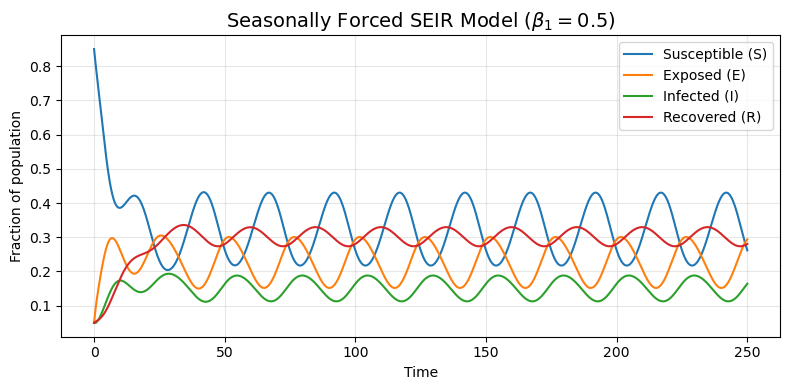

In [59]:
plt.figure(figsize=(8, 4))

plt.plot(t_seasonal, S, label="Susceptible (S)")
plt.plot(t_seasonal, E, label="Exposed (E)")
plt.plot(t_seasonal, I, label="Infected (I)")
plt.plot(t_seasonal, R, label="Recovered (R)")

plt.xlabel("Time")
plt.ylabel("Fraction of population")
plt.title(r"Seasonally Forced SEIR Model ($\beta_1=0.5$)", fontsize=14)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()